# Appendix · Geometry-aware sampling with RM-MALA

NES is trained on random pairs of configurations.  In the notebooks they are drawn uniformly,
which is enough in 2-D.  In higher dimensions it pays off to sample where the geometry
"has more room": uniformly with respect to the **Riemannian volume**, i.e. with density

$$\rho(q)\propto\sqrt{\det G(q)} .$$

The paper does this with the Riemannian-manifold Metropolis-adjusted Langevin algorithm
(RM-MALA).  One step proposes

$$q'\sim\mathcal N\big(\mu(q,\epsilon),\ \epsilon^2G(q)^{-1}\big),$$

a Langevin step whose drift $\mu$ follows the natural gradient of $\log\rho$ (plus curvature
corrections), with a noise shaped by the metric: large steps in cheap directions, small steps
in expensive ones.  A Metropolis test accepts or rejects $q'$ so that the chain samples exactly
from $\rho$.  `geodf.sampling.rm_mala` implements it for any metric.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, sampling, plotting as P
from geodf.robots import PlanarArm

torch.manual_seed(0)
pi = np.pi
arm = PlanarArm()

kinetic energy $M(q)$               50000 samples, acceptance rate 0.87


Jacobi $2(H-P)M$, $H=1.2P_{max}$    50000 samples, acceptance rate 0.91


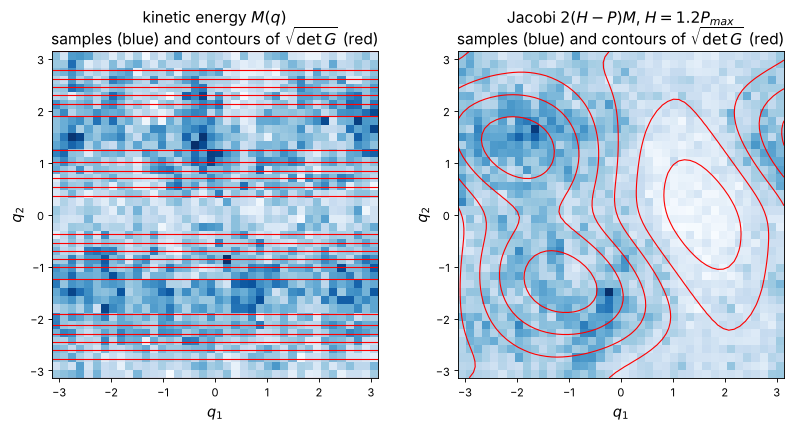

In [2]:
cases = [("kinetic energy $M(q)$", metrics.kinetic_energy(arm), 0.5),
         ("Jacobi $2(H-P)M$, $H=1.2P_{max}$", metrics.jacobi(arm, 1.2 * arm.P_max), 4.0)]
g = np.linspace(-pi, pi, 60)
Qg = torch.as_tensor(np.stack(np.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2))
fig, axs = plt.subplots(1, 2, figsize=(12, 5.3))
for ax, (name, G, eps) in zip(axs, cases):
    samples, acc = sampling.rm_mala(G, [-pi, -pi], [pi, pi], n_chains=2000, n_burn=100, n_samples=25, eps=eps)
    print(f"{name:35s} {len(samples)} samples, acceptance rate {acc:.2f}")
    ax.hist2d(samples[:, 0].numpy(), samples[:, 1].numpy(), bins=40, cmap="Blues")
    dens = torch.sqrt(torch.linalg.det(G(Qg.double()))).reshape(60, 60).numpy()
    ax.contour(g, g, dens.T, 6, colors="r", linewidths=1)
    P.setup_ax(ax, title=f"{name}\nsamples (blue) and contours of $\\sqrt{{\\det G}}$ (red)")
plt.show()

For the kinetic-energy metric $\sqrt{\det M}=4\sqrt{2-\cos^2q_2}$ varies little, so the samples
are almost uniform.  For the Jacobi metric, $\sqrt{\det G}=2(H-P)\sqrt{\det M}$ varies by a factor
~14: it is large around $q_1\approx-\pi/2$ (first link hanging down, a lot of kinetic energy
left) and small around $q_1\approx\pi/2$ (arm pointing up).  The samples follow these contours.  The proposal covariance is
$\epsilon^2G^{-1}$, so the step size has to follow the scale of the metric: the Jacobi metric is
~100x larger than $M$, hence $\epsilon$ is ~10x larger to reach a similar acceptance rate.